# MG628 Week 8 Assignment: Healthcare Administration: Telehealth Recovery App

This notebook contains the code for each task in the Week 8 assignment for your track, set up as in the assignment's code templates, with comments explaining what each part does and why.

**You will complete the whole assignment in this notebook.** The code produces the results; your written answers go in the **✍️ RESPONSE** cells.

### Before you start: save your own copy
If you opened this notebook from a GitHub link, it is a temporary copy, and **anything you type will be lost when you close the tab.** Before writing anything, choose **File → Save a copy in Drive**, and work in that copy (it opens in a new tab named "Copy of …"). Colab then saves your work automatically.

### How to write your responses
- **Every written answer goes in a ✍️ RESPONSE cell.** There is one after each task, and the questions or checklist in each cell match the assignment's deliverables.
- **To type in a response cell,** double-click it (on a phone or tablet, tap it, then tap the pencil icon). Replace each line that says *"Type your response here, replacing this line."* with your own answer. Press **Shift + Enter** when you're done to display it.
- **Keep the headings and questions** in each cell so your grader can see what you are answering.
- **Do not type answers in code cells,** and do not delete or change the code.
- **Use your own numbers** from the output of the code cell just above each response cell.

**How to run it in Google Colab:** choose **Runtime → Run all**, or run the cells in order from the top with **Shift + Enter**. Later cells use variables created in earlier cells, so always run from the top. Before you submit, choose **Runtime → Restart session and run all** to confirm everything runs without errors.

**Tip:** in text cells, type `\$` for a dollar sign. Colab treats text between two plain `$` signs as a math formula.

## Task 1: Load and Explore the Data

In [1]:
# ============================================================
# TASK 1: LOAD AND EXPLORE THE DATA
# ============================================================
# PURPOSE: bring the data into Python and check its quality
# before any analysis. Problems missed here (missing values,
# numbers stored as text) quietly break every later result.

# ---- Import libraries --------------------------------------
# Libraries are toolkits written by others. We import them
# once here, and every later cell can use them. "as pd",
# "as np", and so on are standard short nicknames.
import pandas as pd               # data tables (DataFrames)
import numpy as np                # math on numbers
import matplotlib.pyplot as plt   # charts
import seaborn as sns             # extra chart styles
from scipy import stats           # statistical tests
import statsmodels.api as sm      # regression models

# ---- Load the data -----------------------------------------
# pd.read_csv() reads a CSV file into a DataFrame named df.
# In Colab we read it straight from the MG628 GitHub, so you
# don't need to upload anything.
df = pd.read_csv(
    "https://raw.githubusercontent.com/monroeu/MG628/refs/heads/main/week08/"
    "healthcare_recovery.csv"
)

# ---- Look at the data --------------------------------------
# head(10): the first 10 rows, so you can see what each
# column contains and describe it in your interpretation.
print(df.head(10))

# info(): number of rows, column names, data types, and the
# count of non-missing values per column. If every column
# shows 300 non-null values, there is no missing data.
# (The "None" printed at the end is normal: info() prints
# its report itself, and print() then shows "None".)
print(df.info())

# describe(): count, mean, standard deviation, minimum,
# quartiles, and maximum for each numeric column. Use it to
# check the values are plausible (scores within 1-10, no
# negative dollar amounts).
print(df.describe())

   Patient_ID      Group  Satisfaction_Score  Recovery_Cost
0         263  Treatment                 8.2         465.81
1         115    Control                 8.8        1124.13
2         166  Treatment                 7.2         821.27
3         279  Treatment                 7.3        1194.54
4         294  Treatment                 7.3        1138.10
5         170  Treatment                 8.0         865.16
6          12    Control                 7.0        1276.60
7         236  Treatment                 7.8        1100.91
8         241  Treatment                 8.8         465.92
9         207  Treatment                 8.3         547.25
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Patient_ID          300 non-null    int64  
 1   Group               300 non-null    object 
 2   Satisfaction_Score  300 non-null   

### ✍️ RESPONSE — Task 1: Data quality (2–3 sentences)

The outputs of the code above (first 10 rows and `info()`) are part of your deliverable. Below, write 2–3 sentences:

- ☐ Briefly describe what each column represents
- ☐ Confirm data quality (number of rows, no missing values)

**Your response:**

*Type your response here, replacing this line.*

## Task 2: Calculate Summary Statistics by Group

In [2]:
# ============================================================
# TASK 2: SUMMARY STATISTICS BY GROUP
# ============================================================
# PURPOSE: describe each group with its average (mean) and
# its spread (standard deviation) before running any test.
# These are DESCRIPTIVE statistics: they describe these 300
# patients only.

# groupby('Group') splits the rows into Control and
# Treatment. .agg() then calculates the listed statistics
# for each column within each group:
#   'mean' = the average
#   'std'  = standard deviation (typical distance from
#            the mean; bigger = more spread out)
# .round(2) rounds the table to 2 decimal places.
summary_stats = df.groupby('Group').agg({
    'Satisfaction_Score': ['mean', 'std'],
    'Recovery_Cost': ['mean', 'std']
}).round(2)
print(summary_stats)

# To compare the groups in your interpretation, subtract:
# Treatment mean minus Control mean, for each variable.

          Satisfaction_Score       Recovery_Cost        
                        mean   std          mean     std
Group                                                   
Control                 7.26  1.68       1112.86  272.86
Treatment               8.20  1.14        756.29  230.50


### ✍️ RESPONSE — Task 2, Part 2B: Summary statistics interpretation (3–4 sentences)

The table produced by the code above is your Part 2A. Address ALL of the following:

- ☐ Satisfaction comparison: which group has higher average satisfaction? By how much?
- ☐ Cost comparison: which group has lower average recovery costs? By how much?
- ☐ Calculate the difference: what is the cost savings (or increase) per patient?
- ☐ Initial conclusion: what does this suggest about the Telehealth App's effectiveness?

**Your response:**

*Type your response here, replacing this line.*

## Task 3: Two-Sample T-Test for Satisfaction Scores

In [3]:
# ============================================================
# TASK 3: TWO-SAMPLE T-TEST FOR SATISFACTION SCORES
# ============================================================
# PURPOSE: decide whether the difference in average scores
# between the groups is real (would hold for the wider
# population) or could be due to chance.
#   Null hypothesis (H0): the two population means are equal
#   Alternative (H1):     the two population means differ
# Decision rule at the 0.05 significance level:
#   p < 0.05  -> reject H0 (statistically significant)
#   p >= 0.05 -> fail to reject H0 (never say "accept H0")

# ---- Separate the scores by group --------------------------
# df['Group'] == 'Control' marks the Control rows as True;
# df[...] keeps only those rows; ['Satisfaction_Score']
# then keeps just the score column.
control_sat = df[df['Group'] == 'Control']['Satisfaction_Score']
treatment_sat = df[df['Group'] == 'Treatment']['Satisfaction_Score']

# ---- Run the t-test ----------------------------------------
# stats.ttest_ind() compares the means of two independent
# groups. It returns:
#   t_stat:  the difference in means divided by its standard
#            error (how many "noise units" apart the groups
#            are)
#   p_value: the probability of a difference at least this
#            large if H0 were true
# NOTE: Control is entered first, so t is NEGATIVE when the
# Treatment mean is higher. The sign reflects the order, not
# which group "won"; check the means from Task 2.
t_stat, p_value = stats.ttest_ind(control_sat, treatment_sat)
print(f"T-statistic: {t_stat:.4f}")

# :.4f shows 4 decimal places. A very small p-value prints
# as 0.0000; report it as p < 0.0001 (it is never exactly 0).
print(f"P-value: {p_value:.4f}")

# Apply the decision rule automatically.
if p_value < 0.05:
    print("Result: SIGNIFICANT")
else:
    print("Result: NOT SIGNIFICANT")

T-statistic: -5.6830
P-value: 0.0000
Result: SIGNIFICANT


### ✍️ RESPONSE — Task 3, Part 3A: Statistical test results

Report the results from the t-test output above.

1. T-statistic (rounded to 4 decimal places, e.g. "T-statistic: -7.5234")

   **Answer:** *Type your response here, replacing this line.*

2. P-value (4 decimal places, or "P-value: < 0.0001" if very small)

   **Answer:** *Type your response here, replacing this line.*

### ✍️ RESPONSE — Task 3, Part 3B: Statistical interpretation (3–4 sentences)

Address ALL of the following:

- ☐ Hypothesis decision: do you reject or fail to reject the null hypothesis? (Compare your p-value to 0.05)
- ☐ Meaning: what does this tell you about the Telehealth App's effect on patient satisfaction?
- ☐ Statistical significance: is the difference statistically significant? What does that mean?
- ☐ Practical difference: how many points difference in satisfaction between the groups?

**Your response:**

*Type your response here, replacing this line.*

## Task 4: Construct 95% Confidence Intervals

In [4]:
# ============================================================
# TASK 4: 95% CONFIDENCE INTERVALS FOR RECOVERY_COST
# ============================================================
# PURPOSE: estimate a range of plausible values for each
# group's TRUE average recovery cost, not just the sample
# average. Read it as: "We are 95% confident the true
# average lies between the lower and upper bound." It is
# about the average, not about individual patients.

# t_dist is the t distribution, used to find the critical
# value for the interval.
from scipy.stats import t as t_dist

# ---- A reusable function -----------------------------------
# A function packages steps so we can run them on any group.
# Formula: mean +/- t* x standard error
def confidence_interval_95(data):
    n = len(data)                 # number of patients
    mean = np.mean(data)          # sample average
    std_err = stats.sem(data)     # standard error = SD/sqrt(n)
    # t_dist.ppf(0.975, n-1) is the t value that leaves 2.5%
    # in each tail (about 1.98 when n = 150). Multiplying by
    # the standard error gives the margin of error.
    margin = std_err * t_dist.ppf(0.975, n-1)
    # Return the mean, the lower bound, and the upper bound.
    return mean, mean - margin, mean + margin

# ---- Each group's Recovery_Cost values ------------------------
control_cost = df[df['Group'] == 'Control']['Recovery_Cost']
treatment_cost = df[df['Group'] == 'Treatment']['Recovery_Cost']

# ---- Run the function once per group -----------------------
# The function returns three values; we unpack them into
# three variables per group.
mean_c, lower_c, upper_c = confidence_interval_95(control_cost)
mean_t, lower_t, upper_t = confidence_interval_95(treatment_cost)

# Print each group as: mean [lower bound, upper bound].
print(f"Control: ${mean_c:.2f} [${lower_c:.2f}, ${upper_c:.2f}]")
print(f"Treatment: ${mean_t:.2f} [${lower_t:.2f}, ${upper_t:.2f}]")

# For your interpretation: do the two intervals overlap?
# Intervals that don't overlap are clear evidence of a real
# difference. Also calculate the difference in means
# (Treatment minus Control) in dollars.

Control: $1112.86 [$1068.84, $1156.88]
Treatment: $756.29 [$719.10, $793.48]


### ✍️ RESPONSE — Task 4, Part 4A: Confidence interval calculations

Report both intervals from the output above.

1. Control group: Mean = \$____, 95% CI [\$____, \$____]

   **Answer:** *Type your response here, replacing this line.*

2. Treatment group: Mean = \$____, 95% CI [\$____, \$____]

   **Answer:** *Type your response here, replacing this line.*

### ✍️ RESPONSE — Task 4, Part 4B: Confidence interval interpretation (3–4 sentences)

Address ALL of the following:

- ☐ Control CI meaning: what does it tell you about the true average recovery cost for Control patients?
- ☐ Treatment CI meaning: what does it tell you about the true average recovery cost for Treatment patients?
- ☐ Overlap analysis: do the two intervals overlap? What does this indicate?
- ☐ Cost savings: calculate and state the average cost difference per patient

**Your response:**

*Type your response here, replacing this line.*

## Task 5: Regression Analysis

In [5]:
# ============================================================
# TASK 5: REGRESSION ANALYSIS
# ============================================================
# PURPOSE: explain Recovery_Cost using two predictors at
# once, so we can separate their effects:
#   Recovery_Cost = b0 + b1 x Satisfaction_Score
#                   + b2 x Group_Treatment + error
#   b1: change in Recovery_Cost for a 1-point higher
#       Satisfaction_Score, holding group constant
#   b2: difference between Treatment and Control for
#       patients with the SAME Satisfaction_Score

# ---- Create a dummy (0/1) variable for the group -----------
# Regression needs numbers, not words. This creates 1 for
# Treatment and 0 for Control (True/False becomes 1/0).
# Control is the reference group that b2 is compared to.
df['Group_Treatment'] = (df['Group'] == 'Treatment').astype(int)

# ---- Set up the predictors (X) and the outcome (y) ---------
X = df[['Satisfaction_Score', 'Group_Treatment']]
y = df['Recovery_Cost']

# add_constant() adds a column of 1s so the model has an
# intercept (b0), the predicted value when both predictors
# are 0.
X = sm.add_constant(X)

# ---- Fit the model and show the results --------------------
# OLS (ordinary least squares) finds the coefficients that
# make predictions as close as possible to the actual data.
model = sm.OLS(y, X).fit()

# The summary table. The parts you need:
#   R-squared (top right): share of the variation in
#       Recovery_Cost the model explains (0 to 1)
#   coef column: b0 (const), b1, and b2
#   P>|t| column: p-value for each coefficient
#       (below 0.05 = statistically significant)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          Recovery_Cost   R-squared:                       0.694
Model:                            OLS   Adj. R-squared:                  0.692
Method:                 Least Squares   F-statistic:                     337.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           3.55e-77
Time:                        13:36:50   Log-Likelihood:                -1967.4
No. Observations:                 300   AIC:                             3941.
Df Residuals:                     297   BIC:                             3952.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const               2050.6949     52

### ✍️ RESPONSE — Task 5, Part 5B: Key statistics

The full regression table above is your Part 5A. Report these values from it:

1. R² = ____

   **Answer:** *Type your response here, replacing this line.*

2. Satisfaction_Score: β = \$____ (with its sign, + or −), p = ____

   **Answer:** *Type your response here, replacing this line.*

3. Group_Treatment: β = \$____ (with its sign, + or −), p = ____

   **Answer:** *Type your response here, replacing this line.*

### ✍️ RESPONSE — Task 5, Part 5C: Regression interpretation (4–5 sentences)

Address ALL of the following. Remember: for costs, a negative coefficient is GOOD (reduces costs) and a positive coefficient is BAD (increases costs).

- ☐ Satisfaction coefficient: what happens to recovery costs when satisfaction rises 1 point? State the dollar amount WITH its sign. Is it significant?
- ☐ Treatment coefficient: what is the effect of being in the Treatment group on costs? State the dollar amount WITH its sign. Is it significant after controlling for satisfaction?
- ☐ R-squared: what percentage of variance in recovery costs does the model explain?
- ☐ Overall conclusion: do both satisfaction AND the Telehealth App independently affect costs?

**Your response:**

*Type your response here, replacing this line.*

## Task 6: Data Visualizations

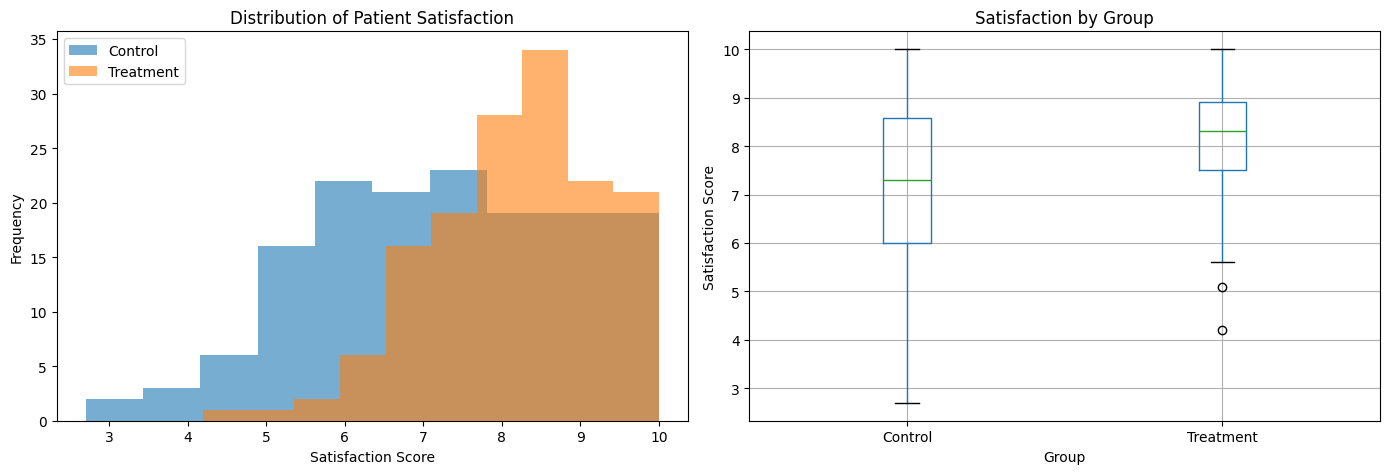

In [6]:
# ============================================================
# TASK 6: DATA VISUALIZATIONS
# ============================================================
# PURPOSE: SEE the difference the t-test measured.
#   Histogram: where each group's scores pile up, and how
#              much the two groups overlap
#   Box plot:  box = middle 50% of scores (Q1 to Q3),
#              line inside = median, whiskers = the range of
#              typical scores, dots = outliers

# Create one figure, 14 wide by 5 tall, to hold both charts.
plt.figure(figsize=(14, 5))

# ---- Histogram ---------------------------------------------
# subplot(1, 2, 1): a grid of 1 row and 2 columns; draw in
# position 1 (left).
plt.subplot(1, 2, 1)
# Draw both groups on the same axes. alpha=0.6 makes the
# bars see-through so the overlap shows; bins=10 splits the
# scores into 10 ranges.
plt.hist(control_sat, alpha=0.6, label='Control', bins=10)
plt.hist(treatment_sat, alpha=0.6, label='Treatment', bins=10)
plt.xlabel('Satisfaction Score')     # x-axis label
plt.ylabel('Frequency')         # y-axis: number of patients
plt.title('Distribution of Patient Satisfaction')
plt.legend()                    # key showing which color is which

# ---- Box plot ----------------------------------------------
# Position 2 (right).
plt.subplot(1, 2, 2)
# One box per group. ax=plt.gca() tells pandas to draw in
# the current (right-hand) chart. Without it, pandas opens a
# new figure and the right-hand chart stays empty (a known
# issue in the assignment template).
df.boxplot(column='Satisfaction_Score', by='Group', ax=plt.gca())
plt.xlabel('Group')
plt.ylabel('Satisfaction Score')
plt.title('Satisfaction by Group')

# pandas adds an automatic title above box plots; this
# removes it.
plt.suptitle('')
# Adjust spacing so labels don't overlap, then display.
plt.tight_layout()
plt.show()

### ✍️ RESPONSE — Task 6, Part 6B: Histogram interpretation (2–3 sentences)

Your two charts above are your Part 6A. Analyze the histogram and address:

- ☐ Shape of distributions: where are most scores concentrated for each group? Which group has more high scores? More low scores?
- ☐ Comparison between groups: how do the two distributions differ in shape or location? What does this tell you about the score difference?

**Your response:**

*Type your response here, replacing this line.*

### ✍️ RESPONSE — Task 6, Part 6C: Box plot interpretation (2–3 sentences)

Analyze the box plot and address:

- ☐ Median comparison: which group has the higher median? Approximately what are the median values?
- ☐ Variability: which group has the wider box (IQR) and longer whiskers? What does this tell you about consistency of scores?
- ☐ Outliers: are there any (dots beyond the whiskers)? What might they represent?
- ☐ Connect to the question: what do these patterns tell you about the Telehealth App's effect? Does one group consistently score higher? Is one group more predictable?

**Your response:**

*Type your response here, replacing this line.*

## Task 7: Recommendation Memo

Synthesize all findings from Tasks 1–6, estimate the implementation costs (app licensing, staff training, IT support), use your cost savings per patient from Task 2 or 4, make a clear YES/NO recommendation, and support it with specific statistics from your analysis.

### ✍️ RESPONSE — Task 7: Recommendation Memo

Write your memo in this cell (1–2 pages when rendered). Keep the headings, replace every placeholder line with your own writing, and use specific numbers from Tasks 2–5. Use professional tone and complete sentences.

**TO:** *(recipient)*
**FROM:** *(your name and role)*
**DATE:** *(date)*
**SUBJECT:** *(subject)*

#### 1. Executive Summary
*Clear YES or NO: should the hospital expand the Telehealth App? State your position in 1–2 sentences with the primary reason.*

#### 2. Key Findings
*Satisfaction impact (Task 3): t-statistic, p-value, statistically significant or not.*

*Cost impact (Task 2): average recovery cost for Control (\$____) and Treatment (\$____), and the savings per patient (\$____).*

*Confidence intervals (Task 4): do the 95% CIs overlap? What does this say about the reliability of the cost difference?*

*Regression results (Task 5): Satisfaction_Score coefficient, Group_Treatment coefficient (with signs), R², and whether both are significant.*

#### 3. Cost-Benefit Analysis
*Implementation costs: estimate app licensing, staff training, and IT support, and explain your estimates. Cost savings per patient: your value from Task 2 or 4. Annual projection: if the hospital treats ____ surgical patients per year, the total potential savings. Break-even: how many patients are needed to justify the implementation costs?*

#### 4. Recommendation
*Paragraph 1: restate your YES/NO recommendation with its primary justification; make it actionable.*

*Paragraph 2: support it with your statistical findings, addressing both patient satisfaction AND costs.*

*Paragraph 3: implementation considerations: concerns or limitations, next steps or conditions, and counterarguments.*

#### 5. Considerations & Limitations
*Assumptions you're making, additional data needed (e.g., readmissions, long-term outcomes), and risks or challenges of expansion.*